# 06. GP versus standard machine-learning models

**Purpose.** Check whether the GP is needed at all. Four common regression
models (support vector regression, random forest, XGBoost and a small neural
network) are trained on exactly the same inputs and the same 10 folds as the
final GP, and all five are scored the same way.

**What this notebook produces** (in `Output_Data/ml_baselines/`)

* `all_model_results.csv`: pooled train and test metrics for every model and property.
* A comparison bar chart of test R².
* Per-model parity and fold plots in `<property>/<model>/` (saved to disk only).

**Things to keep in mind**

* The ML models use the same two inputs as the GP, `[molecular weight, GC
  estimate]`. For method-2 properties (Pc and ΔHvap) they learn the GC error
  from molecular weight only, just like the GP.
* Only the GP gives an uncertainty. The interval columns of the other models are zero.
* This step refits every GP, so a full run takes a while (log P is the slowest).

## 1. Environment and setup

In [1]:
import sys
from pathlib import Path

# Find the repository root (the folder that contains src/gcgp) and make the
# shared code importable. This works whether Jupyter starts in notebooks/ or
# in the repository root.
repoRoot = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "gcgp").is_dir())
sys.path.insert(0, str(repoRoot / "src"))

import pandas as pd

from gcgp.settings import checkCuratedData, describeSetup, outputFolder, setGlobalSeed
from gcgp.properties import PROPERTIES, PROPERTY_ORDER, loadPropertyData
from gcgp.finalConfig import RUN_NAMES, getGpConfig, getSettings
from gcgp.mlBaselines import MODEL_NAMES, runModelComparisonCv
from gcgp.plotting import plotModelComparison

setGlobalSeed()
outputDir = outputFolder("ml_baselines")
pd.set_option("display.precision", 3)
checkCuratedData()
print(describeSetup())

Run mode      : FULL
Input folder  : /Users/sghosh6/Research_Work/BioSci/AMINES_GCGP/gcgp-amines/Input_Data
Output folder : /Users/sghosh6/Research_Work/BioSci/AMINES_GCGP/gcgp-amines/Output_Data
Curated data  : /Users/sghosh6/Research_Work/BioSci/AMINES_GCGP/gcgp-amines/Output_Data/curated_data
GP workers    : 1 (set GCGP_N_WORKERS to fit restarts in parallel)
Global seed   : 42


## 2. Train and score all models

Each property is read from its curated dataset in `Output_Data/curated_data/`,
and the GP uses that property's final settings from notebook 04.

A GP or ML fold that fails numerically (for example a failed Cholesky
decomposition) is dropped from the pooled metrics with a message, and the run
continues. GP restarts are checkpointed in `Output_Data/checkpoints/`, so an
interrupted run resumes where it stopped. Figures are saved to
disk rather than shown, since there are five models for each of seven properties.

In [2]:
allSummaries = []
for code in PROPERTY_ORDER:
    info = PROPERTIES[code]
    settings = getSettings(code)
    runName = RUN_NAMES[code]
    summary = runModelComparisonCv(
        runName, loadPropertyData(code), info["featureCols"], info["targetCol"], getGpConfig(code),
        settings["retrainGp"], outputDir, info["xLabel"], info["yLabel"], code,
        modelNames=MODEL_NAMES, showPlots=False)
    allSummaries.append(summary)
    print(f"{runName}: done")

resultsDf = pd.concat(allSummaries, ignore_index=True)
resultsDf.to_csv(outputDir / "all_model_results.csv", index=False)

Tb: done
Tm: done
Pc: done
Vc: done
Tc: done
Hvap: done
LogP: done


## 3. Results

### 3.1 Pooled test metrics

`Overfitting_dR2` is train R² minus test R². A large value (the random forest is
the usual example) means the model memorises the training molecules.

In [3]:
resultsDf[["Property", "Model", "Overall_Train_R2", "Overall_Test_R2", "Overfitting_dR2",
           "Overall_Test_RMSE", "Overall_Test_MAE"]]

,Property,Model,Overall_Train_R2,Overall_Test_R2,Overfitting_dR2,Overall_Test_RMSE,Overall_Test_MAE
0,Tb,GP,0.852,0.848,0.003,26.566,20.780
1,Tb,SVR,0.840,0.835,0.006,27.747,21.363
2,Tb,RandomForest,0.970,0.847,0.123,26.650,19.674
3,Tb,XGBoost,0.929,0.815,0.114,29.316,21.638
4,Tb,NeuralNetwork,0.848,0.836,0.012,27.629,21.124
5,Tm,GP,0.629,0.616,0.013,55.000,43.589
6,Tm,SVR,0.594,0.584,0.010,57.236,44.856
7,Tm,RandomForest,0.924,0.610,0.313,55.404,42.929
8,Tm,XGBoost,0.722,0.548,0.174,59.666,46.810
9,Tm,NeuralNetwork,0.608,0.603,0.005,55.899,44.297


### 3.2 Test R² by model

Each group of bars is one property. Bars of similar height mean the GP and the simpler
models predict about equally well on these two inputs.

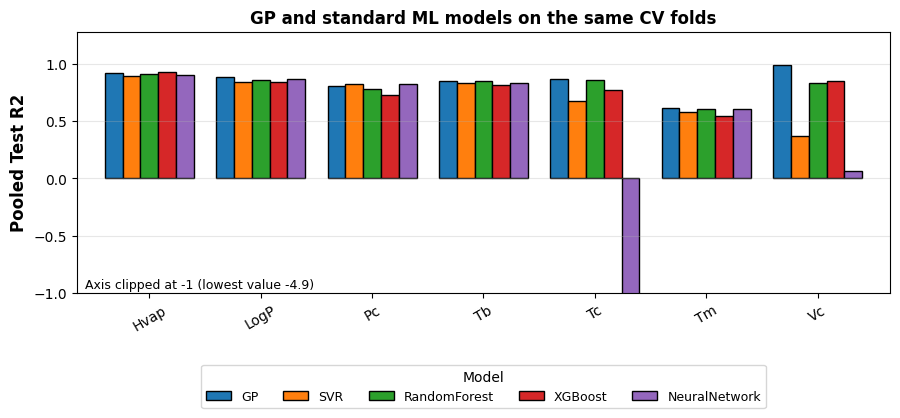

In [4]:
plotModelComparison(resultsDf, metric="Overall_Test_R2", savePath=outputDir / "model_comparison_test_R2.png")

### 3.3 Best model per property

In [5]:
best = resultsDf.loc[resultsDf.groupby("Property")["Overall_Test_R2"].idxmax()]
best[["Property", "Model", "Overall_Test_R2", "Overall_Test_RMSE"]].reset_index(drop=True)

,Property,Model,Overall_Test_R2,Overall_Test_RMSE
0,Hvap,XGBoost,0.925,1.921
1,LogP,GP,0.883,0.675
2,Pc,SVR,0.826,5.303
3,Tb,GP,0.848,26.566
4,Tc,GP,0.866,32.183
5,Tm,GP,0.616,55.000
6,Vc,GP,0.987,18.116


## 4. Summary of the results

Written from the results table above and saved as
`Output_Data/ml_baselines/results_summary.md`.

In [6]:
from gcgp.narrative import describeMlComparison, showAndSave

showAndSave(describeMlComparison(resultsDf), outputDir / "results_summary.md");

## GP versus standard machine-learning models: results

- **Tb**: GP test R² = 0.848, RMSE = 26.57 K; best model is GP (test R² = 0.848, RMSE = 26.57 K).
- **Tm**: GP test R² = 0.616, RMSE = 55.00 K; best model is GP (test R² = 0.616, RMSE = 55.00 K).
- **Pc**: GP test R² = 0.809, RMSE = 5.55 bar; best model is SVR (test R² = 0.826, RMSE = 5.30 bar).
- **Vc**: GP test R² = 0.987, RMSE = 18.12 cm³/mol; best model is GP (test R² = 0.987, RMSE = 18.12 cm³/mol).
- **Tc**: GP test R² = 0.866, RMSE = 32.18 K; best model is GP (test R² = 0.866, RMSE = 32.18 K).
- **ΔHvap**: GP test R² = 0.922, RMSE = 1.96 kJ/mol; best model is XGBoost (test R² = 0.925, RMSE = 1.92 kJ/mol).
- **log P**: GP test R² = 0.883, RMSE = 0.675; best model is GP (test R² = 0.883, RMSE = 0.675).

The GP has the highest test R² for 5 of 7 properties.
